# AII 600. Lab 3

Due before class, 16 September 2026.

Upload this notebook on Canvas, with every code cell executed and the output left in. Credit is on-time submission. I do not mark the lab.

Python kernel. R is allowed: switch to an R kernel and rewrite the code cells. Ask the tutor to translate `check`.

We skipped the Alarm network, and we skipped the orange slides on Binomial and Poisson. They are here. After those stops the problems stack two models, or make you write a sum the library could have hidden. Normal is Lab 4. Work each numeric question on paper first, then type the expression. Written cells have no hashed check. After you write them, ask your tutor to check the written answers.

The notes use `dbinom` and `dpois`. In Python that is `scipy.stats.binom` and `poisson`. The DiMaggio cell is `math.comb` only, so the pmf is still on your cheat sheet.

The test cell under each answer is the grader. It does not contain the number. Fill the answer cell, run it, then run the test cell. If it prints `ok`, that name is right to six decimals. If it says a name is not right, rework that quantity; the cell will not tell you the value. Do not paste a three-decimal number from the slides. The midterm has no test cell.

These are not a substitute for a cheat sheet. After you finish, copy the formulas you actually used onto one.


## How an exercise is built

Run the next cell once. It defines `check`. Each numeric exercise then has two code cells. The first is yours: replace every `None`. The second calls `check`. A line that prints `ok` passed. Leave the output in the notebook.

Do not delete the variable names. You can add scratch cells above an answer cell if you want to compute in public. A written cell has no `check`. Write it, then ask your tutor to read it and say whether the reasoning is right.

You will marginalise a small network, write a two-layer binomial, a double sum over a Poisson grid, a simulation, and two reads of `epl.csv`. `numpy`, `matplotlib`, `scipy.stats`, and `pandas` are allowed after the DiMaggio cell. Ask the tutor for syntax; do the probability yourself.


In [5]:
from hashlib import sha256

def check(name, value, expected, ndigits=6):
    if value is None:
        raise AssertionError(f"replace None for {name}")
    s = f"{round(float(value), ndigits):.{ndigits}f}"
    got = sha256(f"aii600-lab3|{name}|{s}".encode()).hexdigest()[:16]
    assert got == expected, f"{name} is not right"
    print("ok ", name)


## Exercise 1: Alarm

We skipped this. An alarm texts you on motion. $b$ burglary, $e$ earthquake, $a$ alarm, $r$ radio report of a small earthquake. The graph gives

$$
p(b,e,a,r)=p(r\mid e)\,p(a\mid b,e)\,p(b)\,p(e).
$$

| $p(a=1\mid b,e)$ | $b$ | $e$ |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0.1 | 0 | 1 |
| 1 | 1 | 0 |
| 1 | 1 | 1 |

Also $p(r=1\mid e=1)=0.5$, $p(r=1\mid e=0)=0$, $p(b)=2\cdot 10^{-4}$, $p(e)=10^{-2}$.

1. $P(a=1\mid b=0)$, mixing over $e$. Then $P(b=1\mid a=1)$. Do not paste $1/6$: the slide drops $1-p(b)$.
2. Same posterior if you live where $p(b)=10^{-3}$.
3. Explaining away: $P(b=1\mid a=1,r=1)$. Sum the joint over $e$ in the numerator and over $b$ and $e$ in the denominator. The slide rounds; type the sum.
4. The lecture plot. `priors = np.linspace(0, 0.1, 200)`. Posterior of burglary given alarm, as a function of the prior, one vectorised line. Label the axes `prior P(b)` and `P(b | a)`.


In [6]:
p_a_given_b0 = 1e-3         # P(a=1 | b=0)
p_burg_given_alarm = (2*1e-4)/(2*1e-4 + (1e-3)*(1-2*1e-4))   # P(b=1 | a=1), p(b)=2e-4
p_burg_crime = (1e-3)/(1e-3 + (1e-3)*(1-1e-3))         # P(b=1 | a=1), p(b)=1e-3
p_burg_radio = 2e-4/(2e-4 + 0.1 * (1-2e-4))         # P(b=1 | a=1, r=1)
p_a_given_b0, p_burg_given_alarm, p_burg_crime, p_burg_radio


(0.001, 0.1666944490748458, 0.5002501250625313, 0.001996406468356957)

In [7]:
check("p_a_given_b0", p_a_given_b0, "6c71f678c371f3d4")
check("p_burg_given_alarm", p_burg_given_alarm, "a4ff8252b8e4066a")
check("p_burg_crime", p_burg_crime, "1048c4d75b2ed1bd")
check("p_burg_radio", p_burg_radio, "6de981caa0de5bb3")
print("ok  exercise 1 alarm")


ok  p_a_given_b0
ok  p_burg_given_alarm
ok  p_burg_crime
ok  p_burg_radio
ok  exercise 1 alarm


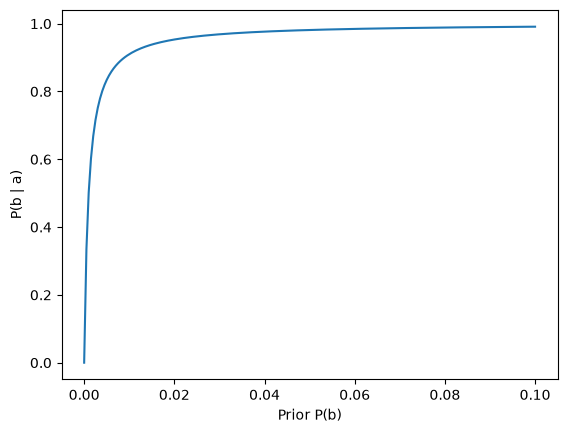

array([0.        , 0.33456005, 0.50150451, 0.60156407, 0.66822586,
       0.71581961, 0.75150301, 0.77924969, 0.8014426 , 0.81959749,
       0.83472454, 0.84752292, 0.85849192, 0.8679976 , 0.87631447,
       0.88365243, 0.8901747 , 0.89601012, 0.90126177, 0.90601307,
       0.91033227, 0.91427576, 0.91789052, 0.92121601, 0.9242856 ,
       0.92712776, 0.92976684, 0.93222387, 0.93451705, 0.93666225,
       0.93867334, 0.94056252, 0.94234054, 0.94401694, 0.94560018,
       0.94709782, 0.94851663, 0.94986265, 0.95114137, 0.9523577 ,
       0.95351609, 0.9546206 , 0.95567489, 0.95668231, 0.95764593,
       0.95856854, 0.95945269, 0.96030076, 0.96111489, 0.9618971 ,
       0.96264921, 0.96337294, 0.96406986, 0.96474143, 0.96538902,
       0.96601388, 0.96661719, 0.96720004, 0.96776347, 0.96830841,
       0.96883578, 0.96934641, 0.96984107, 0.97032051, 0.97078543,
       0.97123646, 0.97167422, 0.9720993 , 0.97251223, 0.97291352,
       0.97330367, 0.97368313, 0.97405233, 0.97441168, 0.97476

In [8]:
import numpy as np
import matplotlib.pyplot as plt

priors = np.linspace(0, 0.1, 200)
p_post_vs_prior = priors / (priors + p_a_given_b0 * (1 - priors))

plt.plot(priors, p_post_vs_prior)
plt.xlabel('Prior P(b)') # vectorised in priors; P(b=1 | a=1) as the prior varies
plt.ylabel('P(b | a)') # vectorised in priors; P(b=1 | a=1) as the prior varies
plt.show()
# plot; label axes prior P(b) and P(b | a)
p_post_vs_prior


In [9]:
import numpy as np
assert np.allclose(np.asarray(priors), np.linspace(0, 0.1, 200)), "use priors = np.linspace(0, 0.1, 200)"
assert p_post_vs_prior is not None, "replace None"
p_post_vs_prior = np.asarray(p_post_vs_prior, dtype=float)
assert len(p_post_vs_prior) == len(priors)
check("p_post_zero", float(p_post_vs_prior[0]), "a6fef36c2fc68eaa")
check("p_post_001", float(p_post_vs_prior[2]), "94af814e42a65edd")
check("p_post_high", float(p_post_vs_prior[-1]), "cb7e7cdd69d33108")
assert np.all(np.diff(p_post_vs_prior) >= -1e-12), "posterior of burglary should rise with the prior"
print("ok  exercise 1 alarm plot")


ok  p_post_zero
ok  p_post_001
ok  p_post_high
ok  exercise 1 alarm plot


The radio says there was a small earthquake. $P(b=1\mid a=1,r=1)$ is much smaller than $P(b=1\mid a=1)$. What did the radio do to the alarm, and why is that not "the alarm was a false positive"? Three to five sentences.

Look at the plot. At the historical prior $2\cdot 10^{-4}$, are you already most of the way to a coin flip, or does $p(b)=10^{-3}$ do the remaining work? One sentence.

**YOUR ANSWER HERE: The report shows that there was an earthquake. That drops the alarm's likelihood ratio for burglary from 1000 to 10, so the posterior falls from 0.167 to 0.002. This is explaining away. It isn't a false positive, because we never observed b=0. The alarm did exactly what its table says it would, and we only revised which cause is more likely.**


## Exercise 2: name the count

We skipped this stop. For each, enter `0` if Binomial and `1` if Poisson. Then compute the two that have parameters.

1. 80 independently tested circuit boards. $X$ = number that fail.
2. Cardiac-arrest calls to 911 between midnight and 6am.
3. A subscriber is shown 12 thumbnails. $X$ = number they click. Each click independent with the same $p$.
4. Goals Hull scores against Man U on Saturday.

Boards: each fails independently with $p=0.03$. $P(X\ge 4)$. Overnight calls: $\mathrm{Poisson}(\lambda=2.2)$. $P(X=0)$. Write the Poisson with `math.exp`. The boards may use `math.comb` or `scipy.stats.binom`.


In [10]:
from math import exp
from scipy.stats import binom, poisson

boards = 0       # 0 binomial, 1 Poisson
calls = 1
thumbs = 0
goals = 1
p_four_fail =   binom.sf(3, 80, 0.03)  # 80 boards, p=0.03, P(X >= 4)
p_no_call = poisson.pmf(0, 2.2)    # Poisson(2.2), P(X = 0)
boards, calls, thumbs, goals, p_four_fail, p_no_call


(0, 1, 0, 1, np.float64(0.21933329469240395), np.float64(0.11080315836233387))

In [11]:
check("boards", boards, "bc5e70f69cdf7697")
check("calls", calls, "3c53032dd1fa29ef")
check("thumbs", thumbs, "2385ef0abbaeb944")
check("goals", goals, "dcf99bae1a4457f7")
check("p_four_fail", p_four_fail, "e9e45571175ffede")
check("p_no_call", p_no_call, "0754916c736b1058")
print("ok  exercise 2 name the count")


ok  boards
ok  calls
ok  thumbs
ok  goals
ok  p_four_fail
ok  p_no_call
ok  exercise 2 name the count


One sentence each. Why binomial for the boards and the thumbnails, and Poisson for the calls and the goals? The distinguishing fact is whether there is a list of independent yes/no trials.

**YOUR ANSWER HERE: the boards and thumbnails are independant events that either happen or it doesnt for each trail. For the calls and goals, its poisson because there no list of how many trials happens, nor a cap on how many goals were scored..**


## Exercise 3: a 7-game series

We skipped the orange slide. Joe DiMaggio's batting average is $0.325$ per at-bat. Four at-bats a game, independent Bernoulli trials. $P(\text{more than 2 hits in a game})$ is the first number.

A short series is 7 games. A *big game* is 3 or 4 hits.

1. $p_{\text{big}}=P(\text{big game})$. Name the distribution, then write the two terms with `math.comb`. Do not call `scipy.stats.binom`. Do not paste $0.104$ from the slide.
2. Let $Y$ be the number of big games in the series. $P(Y\ge 2)$ and $E(Y)$.

Paper first. The next cell is a calculator.


In [12]:
from math import comb

p_hit = 0.325
p_big = comb(4,3) * p_hit**3*(1-p_hit)**1 + comb(4,4)* p_hit**4 * (1-p_hit)**0         # P(3 or 4 hits in 4 at-bats)
p_two_plus =  1 - comb(7,0) * p_big**0 * (1 - p_big)**7 - comb(7,1) * p_big**1 * (1 - p_big)**6    # P(at least 2 big games in 7)
e_big = 7 * p_big          # E(Y)
p_big, p_two_plus, e_big


(0.10384257812500002, 0.15930358038887427, 0.7268980468750001)

In [13]:
check("p_big", p_big, "e5ad5b21be787796")
check("p_two_plus", p_two_plus, "4cf609263adf16d0")
check("e_big", e_big, "18b5ce78a15f697e")
print("ok  exercise 3 series")


ok  p_big
ok  p_two_plus
ok  e_big
ok  exercise 3 series


### Written


Someone treats the series as $28$ independent at-bats and reports $P(\text{at least 6 hits})$. That number is near $0.93$. Why is it not $P(Y\ge 2)$, and which of the two answers a coach actually wants before a series? Four to six sentences.

**YOUR ANSWER HERE: treating it as $28$ individual independant at bats means that you cant tell if there were any big games. 2 big games would mean at least $6$ hits too, but that is $3$ hits within $2$ seperate games. getting 3 hits in a game for $2$ seperate games within the series has a probability of $0.16$ and is far less likely than a hitter getting 6 hits total within a series which has a probabilty of $0.93$. A couch would want to look at the number of big games because big games from a player helps to win the game, whereas looking at the number of hits does not mean the player neccesarrily helps to win a game because hitters can be stranded on bases on bases with with individual hits throughout a series instead of multiple hits within a game. choosing the players with the biggest chance of big games will help win a series one game at a time.**


## Exercise 4: Hull vs Man U

The lecture put Poisson rates on a match: Hull (home) $\lambda_H=0.71$, Man U (away) $\lambda_M=2.41$, independent. Those rates are league average $\times$ attack $\times$ defence. The $n=100$ table was a simulation. Compute the probabilities by summing the joint, then look at the file the averages came from.

$X\sim\mathrm{Poisson}(0.71)$, $Y\sim\mathrm{Poisson}(2.41)$, independent, so $P(X=x,Y=y)=P(X=x)P(Y=y)$. Truncate at $0,1,\ldots,20$. The leftover tail is smaller than $10^{-8}$.

1. $P(\text{Man U wins})=P(Y>X)$, $P(\text{draw})=P(X=Y)$, and $P(0\text{--}1)=P(X=0,Y=1)$, the score that actually happened.
2. Then simulate at least $10{,}000$ independent matches and report the same three frequencies. Leave the exact values in `p_mu_win`, `p_draw`, `p_01`. The simulation is `p_mu_win_sim` and friends.

A library Poisson pmf is allowed. You still write the double sum (or an equivalent grid). Do not paste $0.72$ from the $n=100$ slide.

Then `epl.csv`, in the same folder as this notebook (or [the course copy](https://vsokolov.org/courses/files/600/epl.csv)). 2016--17 Premier League. The columns include `home_team_name`, `away_team_name`, `date_string`, `home_score`, `guest_score`.

3. Number of matches, mean home goals, mean away goals (`guest_score`).
4. Hull vs Manchester United on 27 August 2016: Hull's goals and Man U's goals, from the file, not from the slide.


In [31]:
from math import factorial


lam_h = 0.71
lam_m = 2.41

def pois(k, lam):
    return exp(-lam) * lam**k/factorial(k)

p_mu_win = 0.0
p_draw = 0.0

for x in range(21):
    for y in range(21):
        cell = pois(x,lam_h) * pois(y, lam_m)
        if y > x:
            p_mu_win = p_mu_win + cell
        elif y == x:
            p_draw = p_draw + cell


p_01 = pois(0,lam_h) * pois(1, lam_m)


rng = np.random.default_rng(600)
n_trials = 20000
mu_win_sim = 0
draw_sim = 0
zero_1_sim = 0
for i in range(n_trials):
    hull = rng.poisson(lam_h)
    mu = rng.poisson(lam_m)
    if mu > hull:
        mu_win_sim = mu_win_sim + 1
    elif hull == mu:
        draw_sim = draw_sim + 1
    if hull == 0 and mu == 1:
        zero_1_sim = zero_1_sim + 1
        
        
        


p_mu_win_sim = mu_win_sim / n_trials
p_draw_sim = draw_sim / n_trials
p_01_sim = zero_1_sim / n_trials
p_mu_win, p_draw, p_01, p_mu_win_sim, p_draw_sim, p_01_sim


(0.7503745675009439,
 0.15888544710037691,
 0.1064187758914598,
 0.74895,
 0.1614,
 0.10565)

In [32]:
check("p_mu_win", p_mu_win, "1576f7c56b5eba2d")
check("p_draw", p_draw, "f670a356d1c753bd")
check("p_01", p_01, "8d1cd69a771b4f09")
print("ok  exercise 4 poisson paper")
assert n_trials >= 10000
assert p_mu_win_sim is not None and p_draw_sim is not None and p_01_sim is not None, "replace every None"
assert abs(p_mu_win_sim - p_mu_win) < 0.03, "Man U win rate should match your double sum"
assert abs(p_draw_sim - p_draw) < 0.03, "draw rate should match your double sum"
assert abs(p_01_sim - p_01) < 0.02, "0-1 frequency should match P(X=0,Y=1)"
print("ok  exercise 4 simulation")


ok  p_mu_win
ok  p_draw
ok  p_01
ok  exercise 4 poisson paper
ok  exercise 4 simulation


In [45]:
from pathlib import Path
import pandas as pd

path = Path("epl.csv")
if not path.exists():
    path = "https://vsokolov.org/courses/files/600/epl.csv"
epl = pd.read_csv(path)

n_matches = len(epl)
lam_home_league = epl['home_score'].mean()   # mean of home_score
lam_away_league = epl['guest_score'].mean()   # mean of guest_score
hull_goals = epl.loc[(epl['date_string'].str.startswith('27/08/2016')) & (epl['home_team_name'] == 'Hull'), 'home_score'].iloc[0]      # Hull vs Manchester United, 27 Aug 2016
mu_goals = epl.loc[(epl['date_string'].str.startswith('27/08/2016')) & (epl['home_team_name'] == 'Hull'), 'guest_score'].iloc[0]
n_matches, lam_home_league, lam_away_league, hull_goals, mu_goals


(380,
 np.float64(1.5973684210526315),
 np.float64(1.2026315789473685),
 np.int64(0),
 np.int64(1))

In [46]:
check("n_matches", n_matches, "44e4db24d8424cf9")
check("lam_home_league", lam_home_league, "0d2aa45a0283e7ab")
check("lam_away_league", lam_away_league, "b69edca365751f36")
check("hull_goals", hull_goals, "d2f176db95dd5872")
check("mu_goals", mu_goals, "4ecdf144aae8afd9")
print("ok  exercise 4 epl file")


ok  n_matches
ok  lam_home_league
ok  lam_away_league
ok  hull_goals
ok  mu_goals
ok  exercise 4 epl file


The lecture's $n=100$ table had $0$--$1$ eleven times. Your $P(0\text{--}1)$ is not $0.11$. Is that evidence the Poisson model is wrong, or is $n=100$ the thing that moved? One or two sentences.

Your two league means are close to the slide's $1.60$ and $1.20$. What goes wrong if you replace both by a single $1.4$, and why does the attack/defence model refuse to do that? Two or three sentences.

The file is the whole 2016--17 season. The match is 27 August. Name two problems with using these column means, or season-long attack ratings, as $\lambda$ for that night. Look at `date_string` while you are in the file: would one timestamp format parse every row? Four to six sentences.

Independence, a constant rate for 90 minutes, and $\mathrm{Var}(X)=E(X)$ are three Poisson choices. Pick two. For each, say which way $P(\text{Man U wins})$ would move if you relaxed it (toward Man U, toward Hull, toward a draw, or you cannot tell without more structure). Four to six sentences.

The actual score is the one you read off the file. The model gives Man U about three matches in four. Is that a failed model? Two or three sentences.

**YOUR ANSWER HERE: No, the poisson model is not wrong. $n = 100$ having a different mean to what the model expects is just noise from a different sample size.**

**Using only 1.4 completely erases the home advantage effect. it makes winning at home vs away equally as likely. the attack/defense model keeps the two apart because those belong to a team and not where they play.**

**Using the whole seasons mean doesnt make sense because the match happened mid season and values after the match occured where used for the means. Teams are also not neccesarily the same over the season due to injuries or a player plays badly so is swapped out for another. At the point the two teams played in auagust, there had only been a few games each team had played that season so it would have been difficult to predict using data from that season**

**Relaxing Var = E with extra variance but the same means moves P(Man U wins) toward Hull and toward a draw. More spread puts more weight on Man U scoring 0 and on Hull scoring several, which erodes the favourite's edge. Relaxing independence: you cannot tell without more structure, because the direction depends on the sign of the dependence. If both scores share goals, the shared part cancels in the margin, the margin becomes less variable, and P(Man U wins) rises, with draws also up. Negative dependence, such as a leading team sitting back, would push the other way.**


## Exercise 5: a season, not a match

Same file. Exercise 4 was one night. This is 380 of them.

Poisson, first. Under the lecture model every match is independent $X\sim\mathrm{Poisson}(\lambda_H)$, $Y\sim\mathrm{Poisson}(\lambda_A)$ with the two league means you already computed. Then $P(0\text{--}0)=e^{-\lambda_H}e^{-\lambda_A}$.

1. How many $0$--$0$s are in the file?
2. How many does that Poisson product predict? $380$ times $P(0\text{--}0)$. Use `math.exp` and your two means. Do not paste a rounded $1.60$ and $1.20$.

Binomial, second. A decisive match is one that is not a draw. Treat each decisive match as a home-win / away-win trial.

3. Number of home wins, number of decisive matches, and the share of decisive matches the home side won.
4. If each decisive match were a fair coin, $P(\text{this many home wins, or more})$. $n=296$ is not a `comb` problem; `scipy.stats.binom` is allowed. We have not named a hypothesis test. The number is still a probability.


In [51]:
from math import exp
from scipy.stats import binom

n_nil_nil = ((epl['home_score'] == 0) & (epl['guest_score'] == 0)).sum()   # number of nil-nil games
expected_nil_nil =  n_matches * exp(-lam_home_league) * exp(-lam_away_league)
n_home_win = (epl["home_score"] > epl["guest_score"]).sum()
n_decisive = (epl["home_score"] != epl["guest_score"]).sum()
p_home_decisive = n_home_win / n_decisive
p_ge_home = binom.sf(n_home_win - 1, n_decisive, 0.5)      # P(X >= n_home_win) under Binomial(n_decisive, 0.5)
n_nil_nil, expected_nil_nil, n_home_win, n_decisive, p_home_decisive, p_ge_home


(np.int64(27),
 23.107823797582828,
 np.int64(187),
 np.int64(296),
 np.float64(0.6317567567567568),
 np.float64(3.3957617968558e-06))

In [52]:
check("n_nil_nil", n_nil_nil, "6cbdbb5b1cb1ddf9")
check("expected_nil_nil", expected_nil_nil, "93aac8391edc3c7a")
check("n_home_win", n_home_win, "4807b5d80f08d897")
check("n_decisive", n_decisive, "a2cf7528d9467a18")
check("p_home_decisive", p_home_decisive, "a96aae5a91a4cb56")
check("p_ge_home", p_ge_home, "ae76fbbfb10eccc7")
print("ok  exercise 5 season")


ok  n_nil_nil
ok  expected_nil_nil
ok  n_home_win
ok  n_decisive
ok  p_home_decisive
ok  p_ge_home
ok  exercise 5 season


$27$ nil-nils against an expected $23$ is a small miss. $\sqrt{23}\approx 4.8$. Is that a reason to drop the Poisson product, or is one season inside the noise? Two or three sentences.

You threw away the draws before asking about home advantage. What question does $187/296$ answer that $187/380$ does not, and what did you assume about those $84$ matches? Two or three sentences.

$P(X\ge 187)$ under a fair coin is on the order of $10^{-6}$. Name one modelling choice that could make that tail less extreme without making home sides worse at football (independence of matches, a constant $p$ all season, counting only decisive matches). Two or three sentences.

**YOUR ANSWER HERE: No, 27 is less than 1 standard deviation from the 23.1. 27 is within the acceptable noise range.. it is also slightly different because we only use one league wide rate instead of each teams rate.**

**187/296 tells us how often the home side wins when there is a distinct winner. 187/380 mixes home advatage with how often matches are drawn.**

**If the 296 results share season wide influence, then they are positively correlated, the effective number of independent trials is smaller than 296, and the standard deviation of the home wins grows. even an average correlation of 0.01 can double the standard deviation and move the tail without any change as to how good the home team is.**


In [53]:
print("\n===== CELL RUN =====\n".join(src for src in _ih[-8:] if ("poisson" in src or "n_trials" in src or "epl" in src)))
print("\n===== CURRENT VALUES =====")
for _name in ["random", "lam_h", "lam_m", "n_trials", "mu_win_sim", "draw_sim", "zero_1_sim", "p_mu_win", "p_draw", "p_01", "p_mu_win_sim", "p_draw_sim", "p_01_sim"]:
    print(_name, "=", repr(globals().get(_name, "<not defined>")))

check("n_matches", n_matches, "44e4db24d8424cf9")
check("lam_home_league", lam_home_league, "0d2aa45a0283e7ab")
check("lam_away_league", lam_away_league, "b69edca365751f36")
check("hull_goals", hull_goals, "d2f176db95dd5872")
check("mu_goals", mu_goals, "4ecdf144aae8afd9")
print("ok  exercise 4 epl file")
===== CELL RUN =====
from math import exp
from scipy.stats import binom

n_nil_nil = ((epl['home_score'] == 0) & epl['guest_score'] == 0).sum()   # number of nil-nil games
expected_nil_nil = None
n_home_win = None
n_decisive = None
p_home_decisive = None
p_ge_home = None      # P(X >= n_home_win) under Binomial(n_decisive, 0.5)
n_nil_nil, expected_nil_nil, n_home_win, n_decisive, p_home_decisive, p_ge_home
===== CELL RUN =====
from math import exp
from scipy.stats import binom

n_nil_nil = ((epl['home_score'] == 0) & epl['guest_score'] == 0).sum()   # number of nil-nil games
expected_nil_nil =  n_matches * exp(-lam_home_league) * exp(-lam_away_league)
n_home_win = None
n_decisive = No